In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
import pickle as pkl
import random
from tqdm import tqdm
import matplotlib.pyplot as plt 
import sys
sys.path.append("./gpt2_model/")
from gpt2 import GPT
import os

In [2]:
seed=42

In [3]:
torch_seed = seed
torch.manual_seed(torch_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(torch_seed)

random_seed = seed
random.seed(random_seed)

np_seed = seed
np.random.seed(np_seed)

gpu_id=0
device = f"cuda:{gpu_id}" if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
print(device)

cuda:3


In [4]:
batch_size = 64
block_size = 256        
max_iters = 10000
eval_iters = 10
learning_rate = 1e-4
n_embd = 480
n_head = 8
n_layer = 8
dropout = 0.2

In [5]:
n_states = 6
vocab_size = n_states

In [6]:
dtrajs=pkl.load(open(f"/path/to/pcsk9_gmm_nstates_{n_states}.pkl", "rb"))

In [7]:
dtrajs

[array([5, 5, 5, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 4, 4, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 4, 4, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 4, 4, 4]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([3, 3, 4, ..., 2, 2, 2]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 0, 4, ..., 0, 0, 0]),
 array([4, 3, 3, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 3, 3, 3]),
 array([4, 4, 4, ..., 2, 2, 2]),
 array([4, 4, 4, ..., 4, 4, 4]),
 array([4, 4, 4, ..., 4, 4, 4]),
 array([0, 0, 0, ..., 3, 3, 3]),
 array([4, 4, 4, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([5, 5, 4, ..., 5, 5, 5]),
 array([4, 4, 0, ..., 0, 0, 0]),
 array([4, 4, 4, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 4, 0, ..., 5, 5, 5]),
 array([4, 4, 4, ..., 0, 0, 0]),
 array([4, 4, 4, ..., 3, 3, 3]),
 array([4, 4, 4, ..., 2, 2, 2]),
 array([3, 3, 3, ..., 1, 1, 1]),
 array([2, 2, 2, ..., 2, 2, 2]),
 array([4,

In [8]:
print(len(np.concatenate(dtrajs)))

1912879


In [9]:
lengths = np.array([len(t) for t in dtrajs])
print(f"Number of trajectories: {len(dtrajs)}")
print(f"Length range: {lengths.min()} - {lengths.max()} (mean {lengths.mean():.1f})")

Number of trajectories: 399
Length range: 1 - 20002 (mean 4794.2)


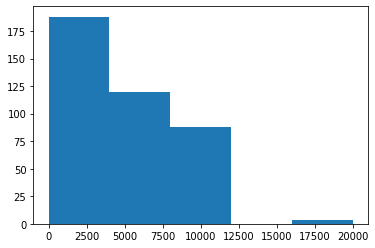

In [10]:
plt.hist(lengths, bins=5)[2]
plt.show()

In [11]:
usable = [np.asarray(t) for t in dtrajs if len(t) >= block_size + 1]
dropped = len(dtrajs) - len(usable)
print(f"Usable trajectories (len > block_size): {len(usable)} / {len(dtrajs)} "
      f"({dropped} dropped as too short for block_size={block_size})")

n_usable = len(usable)
lengths = np.array([len(t) for t in usable])
total_len = lengths.sum()
print(f"Total flattened length across {n_usable} usable trajs: {total_len}")

Usable trajectories (len > block_size): 398 / 399 (1 dropped as too short for block_size=256)
Total flattened length across 398 usable trajs: 1912878


In [12]:
# --- 2. Precompute flattened start/end offsets for each usable traj ---
# This assumes usable[0], usable[1], ..., usable[n-1] are concatenated IN THIS ORDER
# to form the flattened array of length total_len.
offsets_end = np.cumsum(lengths)
offsets_start = offsets_end - lengths   # start index (inclusive) of traj i in flattened array
# offsets_end[i] is exclusive end index of traj i

# --- 3. 70/15/15 split on trajectory indices ---
rng = np.random.default_rng(42)
perm = rng.permutation(n_usable)

n_train = int(0.70 * n_usable)
n_val   = int(0.15 * n_usable)
# whatever's left goes to test, avoids rounding gaps
n_test  = n_usable - n_train - n_val

train_idx = np.sort(perm[:n_train])
val_idx   = np.sort(perm[n_train:n_train + n_val])
test_idx  = np.sort(perm[n_train + n_val:])

print(f"Train trajs: {len(train_idx)}, Val trajs: {len(val_idx)}, Test trajs: {len(test_idx)}")
assert len(train_idx) + len(val_idx) + len(test_idx) == n_usable

# --- 4. Build the actual tensor lists for each split ---
train_trajs = [torch.tensor(usable[i], dtype=torch.long) for i in train_idx]
val_trajs   = [torch.tensor(usable[i], dtype=torch.long) for i in val_idx]
test_trajs  = [torch.tensor(usable[i], dtype=torch.long) for i in test_idx]

print(f"Train trajectories: {len(train_trajs)}")
print(f"Val trajectories:   {len(val_trajs)}")
print(f"Test trajectories:  {len(test_trajs)}")
print(f"Vocabulary: {vocab_size}")

# --- 5. Map trajectory indices -> flattened frame indices ---
def traj_indices_to_frame_indices(traj_idx_array, offsets_start, offsets_end):
    """
    Given an array of trajectory indices (into `usable`), return a single
    1D array of all the flattened frame indices belonging to those trajectories.
    """
    frame_idx_list = [
        np.arange(offsets_start[i], offsets_end[i]) for i in traj_idx_array
    ]
    return np.concatenate(frame_idx_list) if frame_idx_list else np.array([], dtype=int)

train_frame_idx = traj_indices_to_frame_indices(train_idx, offsets_start, offsets_end)
val_frame_idx   = traj_indices_to_frame_indices(val_idx,   offsets_start, offsets_end)
test_frame_idx  = traj_indices_to_frame_indices(test_idx,  offsets_start, offsets_end)

print(f"Train frames: {len(train_frame_idx)}")
print(f"Val frames:   {len(val_frame_idx)}")
print(f"Test frames:  {len(test_frame_idx)}")
print(f"Sum: {len(train_frame_idx) + len(val_frame_idx) + len(test_frame_idx)} "
      f"(should equal total_len = {total_len})")

# Sanity check: no overlap, full coverage
all_frames = np.concatenate([train_frame_idx, val_frame_idx, test_frame_idx])
assert len(np.unique(all_frames)) == total_len, "Frame indices overlap or miss some frames!"
assert set(all_frames) == set(range(total_len))

Train trajs: 278, Val trajs: 59, Test trajs: 61
Train trajectories: 278
Val trajectories:   59
Test trajectories:  61
Vocabulary: 6
Train frames: 1292875
Val frames:   317942
Test frames:  302061
Sum: 1912878 (should equal total_len = 1912878)


In [13]:
save_dir = "./SPLITS"
os.makedirs(save_dir, exist_ok=True)

# --- 1. Build numpy versions of the splits (instead of torch tensors) ---
train_trajs_np = [usable[i] for i in train_idx]
val_trajs_np   = [usable[i] for i in val_idx]
test_trajs_np  = [usable[i] for i in test_idx]

# --- 2. Save the trajectory splits (list of numpy arrays) as pkl ---
with open(os.path.join(save_dir, "train_trajs.pkl"), "wb") as f:
    pkl.dump(train_trajs_np, f)

with open(os.path.join(save_dir, "val_trajs.pkl"), "wb") as f:
    pkl.dump(val_trajs_np, f)

with open(os.path.join(save_dir, "test_trajs.pkl"), "wb") as f:
    pkl.dump(test_trajs_np, f)

print("Saved train/val/test trajectory pkl files (as numpy arrays).")

# --- 3. Save trajectory-level indices (into `usable`) as npy ---
np.save(os.path.join(save_dir, "train_traj_idx.npy"), train_idx)
np.save(os.path.join(save_dir, "val_traj_idx.npy"),   val_idx)
np.save(os.path.join(save_dir, "test_traj_idx.npy"),  test_idx)

print("Saved train/val/test trajectory-index npy files.")

# --- 4. Save frame-level indices (into the flattened dtraj array) as npy ---
np.save(os.path.join(save_dir, "train_frame_idx.npy"), train_frame_idx)
np.save(os.path.join(save_dir, "val_frame_idx.npy"),   val_frame_idx)
np.save(os.path.join(save_dir, "test_frame_idx.npy"),  test_frame_idx)

print("Saved train/val/test frame-index npy files.")

Saved train/val/test trajectory pkl files (as numpy arrays).
Saved train/val/test trajectory-index npy files.
Saved train/val/test frame-index npy files.


In [14]:
def get_batch(split):
    trajs = train_trajs if split == "train" else val_trajs
 
    # weight by (len - block_size) = number of valid start positions,
    # so long trajectories aren't under-represented relative to how
    # many distinct windows they actually contain.
    weights = np.array([len(t) - block_size for t in trajs], dtype=np.float64)
    probs = weights / weights.sum()
 
    traj_idx = np.random.choice(len(trajs), size=batch_size, p=probs)
 
    xs, ys = [], []
    for ti in traj_idx:
        traj = trajs[ti]
        max_start = len(traj) - block_size - 1
        start = np.random.randint(0, max_start + 1)
        xs.append(traj[start:start + block_size])
        ys.append(traj[start + 1:start + block_size + 1])
 
    x = torch.stack(xs)
    y = torch.stack(ys)
    return x.to(device), y.to(device)

In [15]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [16]:
model = GPT(
    vocab_size=vocab_size,
    n_embd=n_embd,
    n_head=n_head,
    n_layer=n_layer,
    block_size=block_size,
    dropout=dropout,
    device=device,
).to(device)
 
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

In [17]:
train_loss, val_loss, epochs = [], [], []
best_loss = float("inf")
 
for it in tqdm(range(max_iters)):
    if it % eval_iters == 0:
        losses = estimate_loss()
        train_loss.append(losses["train"].item())
        val_loss.append(losses["val"].item())
        epochs.append(it)
        print(f"step: {it}, train loss: {losses['train']:.3f}, val loss: {losses['val']:.3f}")
        if losses["val"].item() < best_loss:
            best_loss = losses["val"].item()
            with open(f"pcsk9_gpt_model_best_{n_states}_state.pkl", "wb") as f:
                pkl.dump(model, f)
 
    xb, yb = get_batch("train")
    logits, loss = model.forward(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

  0%|                                                                                                                         | 0/10000 [00:00<?, ?it/s]

step: 0, train loss: 2.240, val loss: 2.266


  0%|                                                                                                                | 10/10000 [00:05<47:52,  3.48it/s]

step: 10, train loss: 0.041, val loss: 0.025


  0%|▏                                                                                                               | 20/10000 [00:09<47:28,  3.50it/s]

step: 20, train loss: 0.037, val loss: 0.027


... (1,991 outputs left out)

step: 9980, train loss: 0.028, val loss: 0.020


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 9990/10000 [1:09:08<00:02,  3.65it/s]

step: 9990, train loss: 0.021, val loss: 0.014


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [1:09:13<00:00,  2.41it/s]


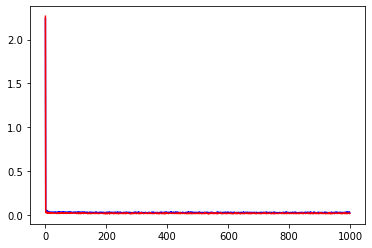

In [18]:
plt.plot(train_loss, 'b')
plt.plot(val_loss, 'r')

In [19]:
plt.rcParams['axes.linewidth'] = 3
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

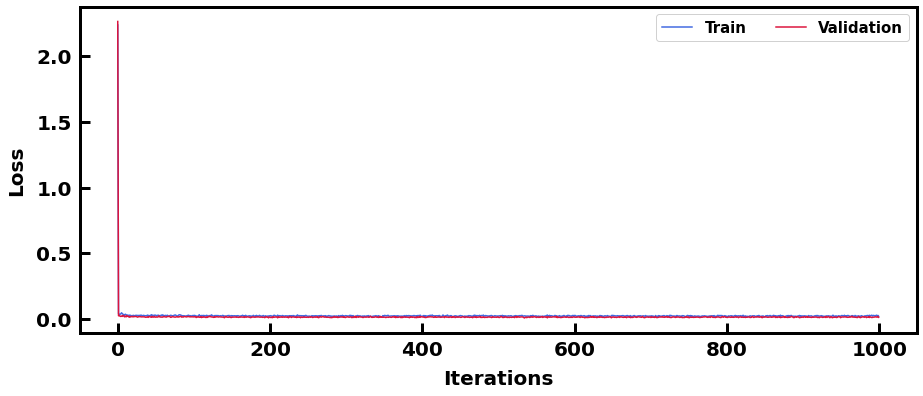

In [20]:
fig, ax = plt.subplots(figsize=(15, 6))

color_train = 'royalblue'
color_val = 'crimson'

ax.plot(train_loss, color=color_train, label='Train')
ax.plot(val_loss, color=color_val, label='Validation')

ax.tick_params(axis='both', which='major', direction='in', length=10, width=3,
                 pad=8, labelsize=20, top=False)  # top=False since ax2 owns the top spine visually
ax.legend(fontsize=15,  loc='upper right', frameon=True, framealpha=0.9, ncols=2,)

ax.set_xlabel('Iterations', fontsize=20, labelpad=10)
ax.set_ylabel('Loss',  fontsize=20, labelpad=10)

plt.savefig(f"Loss.png", dpi = 300, format = 'png', bbox_inches = 'tight')
plt.savefig(f"Loss.pdf", dpi = 300, format = 'pdf', bbox_inches = 'tight')
plt.savefig(f"Loss.svg", dpi = 300, format = 'svg', bbox_inches = 'tight')
plt.show()